# 02. RFM Analysis

This notebook builds a household-level RFM (Recency, Frequency, Monetary) table from `transaction_data`, answering: which households are currently most valuable, and how often do they buy?

Most of the aggregation happens in SQL directly against the PostgreSQL database built in `01_data_setup_and_loading.ipynb`; pandas is used afterward for scoring, outlier detection, and visualization, not for the aggregation itself.

Four design decisions shape the table:
- **Recency** is measured against the dataset's last available `day`, not the system's current date: dunnhumby uses a sequential `day` field (1–711), not real calendar dates.
- **Frequency** counts distinct `basket_id`s per household, not transaction line count, since `transaction_data` is at the product-line grain and a 15-item basket should count as one visit, not fifteen.
- **Monetary** is total accumulated `sales_value` per household (classic RFM), with average ticket size (`monetary / frequency`) kept as a separate supporting variable, not a substitute for M.
- Rows with `sales_value <= 0` are excluded from both Frequency and Monetary, since they most likely represent returns or adjustments rather than purchase visits. This was already quantified in `01_data_setup_and_loading.ipynb` (Section 5.3): 0.7% of rows (18,850), and we confirm that figure again here directly against the loaded table before using it. `QUANTITY <= 0` is not used as an additional filter; Section 2 checks how much the two conditions actually overlap before relying on that choice.

Outlier detection on the resulting RFM table happens at the end of this notebook, detection only, no treatment. Treatment is deferred to `03_clustering.ipynb`, since it depends on which clustering algorithm is chosen and how sensitive it is to scale.

## 1. Environment Setup

We reconnect to the same `dunnhumby` PostgreSQL database populated in `01_data_setup_and_loading.ipynb`. No CSVs are read directly in this notebook, all source data comes from the tables already loaded and verified there. The cell fails fast if a required environment variable is missing, and confirms `transaction_data` holds the row count established in that notebook before anything downstream relies on it.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # must be set before numpy/matplotlib load OpenMP

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

load_dotenv()

DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")
DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")

required = {"DB_HOST": DB_HOST, "DB_PORT": DB_PORT, "DB_NAME": DB_NAME,
            "DB_USER": DB_USER, "DB_PASSWORD": DB_PASSWORD}
missing = [name for name, value in required.items() if not value]
if missing:
    raise EnvironmentError(f"Missing variables in .env: {missing}")

engine = create_engine(
    URL.create(
        drivername="postgresql+psycopg2",
        username=DB_USER,
        password=DB_PASSWORD,
        host=DB_HOST,
        port=int(DB_PORT),
        database=DB_NAME,
    )
)

with engine.connect() as conn:
    version = conn.execute(text("SELECT version();")).fetchone()
    print(version)

    n_transactions = conn.execute(text("SELECT COUNT(*) FROM transaction_data")).scalar()
    if n_transactions == 0:
        raise RuntimeError(
            "transaction_data is empty. Run 01_data_setup_and_loading.ipynb before this notebook."
        )
    print(f"transaction_data rows available: {n_transactions:,}")

('PostgreSQL 18.3 on x86_64-windows, compiled by msvc-19.44.35225, 64-bit',)
transaction_data rows available: 2,595,732


## 2. Confirming the sales_value <= 0 Exclusion Against the Loaded Table

Section 5.3 of the previous notebook quantified this against the raw CSV (0.7%, 18,850 rows). We confirm it again here directly via SQL against `transaction_data` as loaded in PostgreSQL, since this notebook's RFM query will filter on this condition and should be validated against the same source it queries, not assumed from a prior file-based check. We also check how much `sales_value <= 0` overlaps with `quantity <= 0` (0.6% of rows per Notebook 01, Section 5.3), since only `sales_value` is used as the RFM exclusion filter and `quantity` is not.

In [2]:
query = """
SELECT
    COUNT(*) AS total_rows,
    COUNT(*) FILTER (WHERE sales_value <= 0) AS non_positive_sales,
    COUNT(*) FILTER (WHERE quantity <= 0) AS non_positive_qty,
    COUNT(*) FILTER (WHERE sales_value <= 0 AND quantity <= 0) AS both_non_positive,
    COUNT(*) FILTER (WHERE sales_value <= 0 AND quantity > 0) AS sales_only,
    COUNT(*) FILTER (WHERE sales_value > 0 AND quantity <= 0) AS qty_only
FROM transaction_data;
"""

with engine.connect() as conn:
    result = conn.execute(text(query)).mappings().one()

total = result["total_rows"]
non_positive_sales = result["non_positive_sales"]
pct_non_positive_sales = non_positive_sales / total * 100

print(f"Total rows: {total:,}")
print(f"Rows with sales_value <= 0: {non_positive_sales:,} ({pct_non_positive_sales:.2f}%)")
print(f"Rows with quantity <= 0:    {result['non_positive_qty']:,}")
print(f"  both sales_value <= 0 and quantity <= 0: {result['both_non_positive']:,}")
print(f"  sales_value <= 0 only (quantity > 0):    {result['sales_only']:,}")
print(f"  quantity <= 0 only (sales_value > 0):    {result['qty_only']:,}")

Total rows: 2,595,732
Rows with sales_value <= 0: 18,879 (0.73%)
Rows with quantity <= 0:    14,466
  both sales_value <= 0 and quantity <= 0: 14,428
  sales_value <= 0 only (quantity > 0):    4,451
  quantity <= 0 only (sales_value > 0):    38


The count against the loaded table (18,879 rows, 0.73%) is 29 rows higher than the CSV-based count in the previous notebook (18,850 rows, 0.7%), with the total row count matching exactly in both (2,595,732). The CSV has no negative values and exactly 18,850 zeros, so the 29 extra rows can only be small positive values that became zero on load: `sales_value` is stored as `NUMERIC(10,2)`, which rounds anything below half a cent to 0.00. Those lines are worth less than a cent either way, so the difference doesn't affect any result.

The overlap check shows most `quantity <= 0` rows are *not* also `sales_value <= 0`: they are separate conditions, consistent with weight-priced items in this dataset typically carrying `quantity = 0` regardless of a positive `sales_value`. Filtering only on `sales_value` does not implicitly also exclude most of those rows; it targets returns and adjustments specifically, which is what Frequency and Monetary are meant to exclude. **18,879 rows (0.73%) is the figure used for the rest of this notebook.**

## 3. Building the RFM Table

Recency, Frequency, and Monetary are computed directly in SQL using CTEs. One methodological detail worth making explicit: `reference_day` (the reference point) is computed from the *entire* `transaction_data` table, unfiltered: it represents the dataset's time boundary, independent of any single household's activity. Each household's *last purchase day*, however, is computed only from rows with `sales_value > 0`, since a day where a household only had a return recorded isn't a genuine purchase occasion and shouldn't count as their "last visit" for Recency purposes.

Because `household_agg` is built only from rows with `sales_value > 0`, a household whose every transaction was non-positive would not appear in it at all, and would silently disappear from the RFM table with no row produced for it. The cell below checks for that explicitly, rather than relying on the final row count happening to match.

In [3]:
rfm_query = """
WITH filtered_transactions AS (
    SELECT household_key, basket_id, day, sales_value
    FROM transaction_data
    WHERE sales_value > 0
),
reference_day AS (
    SELECT MAX(day) AS reference_day
    FROM transaction_data
),
household_agg AS (
    SELECT
        household_key,
        MAX(day) AS last_purchase_day,
        COUNT(DISTINCT basket_id) AS frequency,
        SUM(sales_value) AS monetary
    FROM filtered_transactions
    GROUP BY household_key
)
SELECT
    h.household_key,
    r.reference_day,
    h.last_purchase_day,
    r.reference_day - h.last_purchase_day AS recency,
    h.frequency,
    h.monetary,
    ROUND(h.monetary / h.frequency, 2) AS avg_ticket
FROM household_agg h
CROSS JOIN reference_day r
ORDER BY h.household_key;
"""

rfm = pd.read_sql(text(rfm_query), engine)

with engine.connect() as conn:
    all_households = pd.read_sql(
        text("SELECT DISTINCT household_key FROM transaction_data"), conn
    )["household_key"]

dropped_households = sorted(set(all_households) - set(rfm["household_key"]))

print(f"Households in transaction_data: {all_households.nunique()}")
print(f"Households in RFM table: {len(rfm)}")
print(f"Households with no sales_value > 0 transaction (dropped from RFM): {dropped_households if dropped_households else 'none'}")

assert not dropped_households, (
    "One or more households have no qualifying (sales_value > 0) transaction "
    "and are missing from the RFM table; decide explicitly how to handle them."
)

rfm.head()

Households in transaction_data: 2500
Households in RFM table: 2500
Households with no sales_value > 0 transaction (dropped from RFM): none


,household_key,reference_day,last_purchase_day,recency,frequency,monetary,avg_ticket
0,1,711,706,5,85,4330.16,50.94
1,2,711,668,43,45,1954.34,43.43
2,3,711,703,8,47,2653.21,56.45
3,4,711,627,84,30,1200.11,40.00
4,5,711,703,8,40,779.06,19.48


2,500 households, matching the distinct household count confirmed in `01_data_setup_and_loading.ipynb` (Section 4). The explicit comparison above confirms directly that no household was dropped for lacking a qualifying transaction, rather than inferring it from the row count alone (the cell fails otherwise). Spot-checking the first rows, the numbers already tell a coherent story: household 1 (recency 5, frequency 85) looks like an active, frequent shopper, while household 4 (recency 84, frequency 30) looks like someone who may be drifting away, exactly the kind of signal RFM is meant to surface.

The raw RFM table is complete and traceable, with `reference_day` and `last_purchase_day` kept as columns for transparency (per the original project design) rather than discarded once recency is computed.

### 3.1 Sanity Check: Frequency Distribution Bounds

Before scoring, we check the extremes of `frequency`, specifically how many households have the minimum possible value (a single basket in 711 days). This isn't an error to fix, but it's worth knowing how much of the table sits at that edge before interpreting any RFM segment built on it.

In [4]:
print(rfm["frequency"].describe())
print(f"\nHouseholds with frequency == 1: {(rfm['frequency'] == 1).sum()}")

count    2500.000000
mean      110.216800
std       115.271537
min         1.000000
25%        38.000000
50%        78.000000
75%       142.000000
max      1298.000000
Name: frequency, dtype: float64

Households with frequency == 1: 3


Only 3 households sit at the minimum (`frequency == 1`): a negligible edge case, not something requiring special handling.

The broader distribution is more informative: the standard deviation (115.3) is nearly as large as the mean (110.2), and the maximum (1,298 baskets) is almost 12 times the mean. This is the signature of a right-skewed distribution with a long tail, consistent with the outlier detection this notebook already flagged for its closing section. We don't treat this yet; we note it and move on to scoring, then return to it deliberately in Section 6, separating detection from treatment as planned.

In [5]:
print("frequency — distinct values:", rfm["frequency"].nunique(), "/", len(rfm))
print("monetary  — describe:")
print(rfm["monetary"].describe())

frequency — distinct values: 395 / 2500
monetary  — describe:
count     2500.000000
mean      3222.985232
std       3349.026076
min          8.170000
25%        970.740000
50%       2157.750000
75%       4413.320000
max      38319.790000
Name: monetary, dtype: float64


A quick histogram confirms this shape directly, rather than relying only on the mean/std comparison, a useful heuristic, but one that a bimodal distribution could also satisfy without being right-skewed. We check `monetary` here too, since Section 6 references this section's skew confirmation for both variables, not just `frequency`. Neither variable comes close to one distinct value per household: `frequency` takes 395 distinct values across 2,500 households (printed above), and `recency` has heavy ties at the low end, since many households last bought in the final days of the data. Section 4 deals with those ties before scoring.

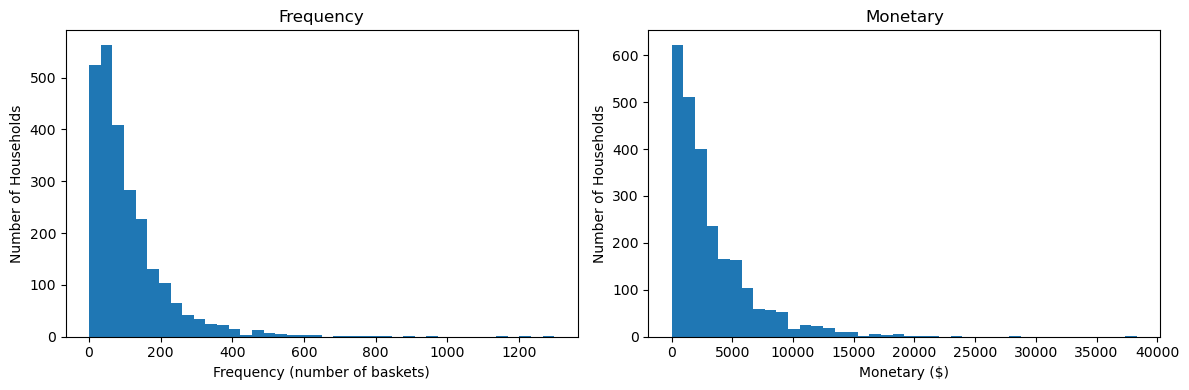

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(rfm["frequency"], bins=40)
axes[0].set_title("Frequency")
axes[0].set_xlabel("Frequency (number of baskets)")
axes[0].set_ylabel("Number of Households")
axes[1].hist(rfm["monetary"], bins=40)
axes[1].set_title("Monetary")
axes[1].set_xlabel("Monetary ($)")
axes[1].set_ylabel("Number of Households")
plt.tight_layout()
plt.show()

Both histograms show the expected signature of right skew: most households concentrated at low values, with a long, thin tail extending toward the extremes, consistent with the mean/std comparison above, and unimodal in both cases, with no sign of the bimodality the heuristic alone couldn't rule out. Because the tail is long and thin, most of its detail is compressed into a handful of bars at this linear scale; Section 6's boxplots and the top-outlier table in Section 7 give a clearer look at exactly which households sit out there.

## 4. RFM Scoring

Each of Recency, Frequency, and Monetary is split into quintiles (1–5), the standard RFM convention. Recency is scored in reverse: a *lower* number of days since last purchase should get a *higher* score, since it represents more recent (better) behavior. Frequency and Monetary are scored directly, higher values get higher scores.

Given the skew just confirmed in Section 3.1, quintile-based scoring (`pd.qcut`, based on rank rather than raw value) is a deliberate choice here: it's far less sensitive to the long tail than binning by fixed value ranges would be. `.rank(method="first")` is applied to all three variables before `qcut`. It gives tied households consecutive ranks in the order they appear in the table (sorted by `household_key` in the SQL query), so `qcut` always gets 2,500 distinct ranks and five bins of exactly 500. The cost is that households with the same value can land in different quintiles when a cut point falls inside a run of ties, and which side they land on depends only on their `household_key`. This matters most for `recency`: the 500 households scored 5 have a mean recency of 0.27 days (printed in the monotonicity check below), so at least 367 of them last bought on the final day of the data, and the cut between scores 4 and 5 can separate households that bought on exactly the same day. Ranking with `method="average"` would keep ties together but produce bins of unequal size; equal-size bins were kept here, with this limitation stated.

In [7]:
rfm["r_score"] = pd.qcut(
    rfm["recency"].rank(method="first", ascending=False), q=5, labels=[1, 2, 3, 4, 5]
).astype(int)
rfm["f_score"] = pd.qcut(rfm["frequency"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["rfm_score"] = rfm["r_score"].astype(str) + rfm["f_score"].astype(str) + rfm["m_score"].astype(str)

rfm[["household_key", "recency", "frequency", "monetary", "r_score", "f_score", "m_score", "rfm_score"]].head(10)

,household_key,recency,frequency,monetary,r_score,f_score,m_score,rfm_score
0,1,5,85,4330.16,3,3,4,334
1,2,43,45,1954.34,1,2,3,123
2,3,8,47,2653.21,3,2,3,323
3,4,84,30,1200.11,1,1,2,112
4,5,8,40,779.06,3,2,2,322
5,6,4,249,5996.16,3,5,5,355
6,7,2,59,3400.05,4,2,4,424
7,8,5,113,5534.97,3,4,5,345
8,9,22,20,797.42,2,1,2,212
9,10,26,9,234.34,2,1,1,211


Scoring ran without error. The direction check holds on this sample: household 7 (recency 2, the most recent) scored `r_score=4`, while household 4 (recency 84, the worst) scored `r_score=1`, confirming the reversed labeling is working as intended (`recency.rank(ascending=False)` ranks the smallest recency highest, so it lands in the top quintile label).

### 4.1 Validating Score Monotonicity

A visual check on 10 rows isn't enough to trust the scoring logic across all 2,500 households. We confirm monotonicity directly: average `recency` should strictly decrease as `r_score` increases, and average `frequency`/`monetary` should strictly increase as their respective scores increase.

In [8]:
recency_by_score = rfm.groupby("r_score")["recency"].mean()
frequency_by_score = rfm.groupby("f_score")["frequency"].mean()
monetary_by_score = rfm.groupby("m_score")["monetary"].mean()

print("Mean recency by r_score:")
print(recency_by_score)

print("\nMean frequency by f_score:")
print(frequency_by_score)

print("\nMean monetary by m_score:")
print(monetary_by_score)

assert recency_by_score.is_monotonic_decreasing
assert frequency_by_score.is_monotonic_increasing
assert monetary_by_score.is_monotonic_increasing

Mean recency by r_score:
r_score
1    103.228
2     16.232
3      6.018
4      2.136
5      0.266
Name: recency, dtype: float64

Mean frequency by f_score:
f_score
1     18.370
2     45.014
3     78.330
4    127.750
5    281.620
Name: frequency, dtype: float64

Mean monetary by m_score:
m_score
1     398.43384
2    1176.31218
3    2177.42682
4    3814.37682
5    8548.37650
Name: monetary, dtype: float64


Strict monotonicity confirmed across all three scores, no exceptions (the cell asserts it, not just prints it). `recency` decreases from 103.2 days (`r_score=1`) to 0.3 days (`r_score=5`); `frequency` increases from 18.4 (`f_score=1`) to 281.6 (`f_score=5`); `monetary` increases from $398 (`m_score=1`) to $8,548 (`m_score=5`), with a roughly 21x spread between the bottom and top monetary quintile, a first concrete glimpse of how unevenly value is distributed across households before we even get to clustering.

The RFM scoring logic is validated. Section 4 is complete.

## 5. Segment Distribution

Before any clustering (reserved for `03_clustering.ipynb`), we look at what the raw RFM scores already tell us using the classic rule-based segments: Champions, At Risk, Lost, etc. This isn't the final segmentation for the project (that's what Notebook 03 is for), but a quick descriptive pass is useful here to sanity-check that the scores behave sensibly before handing them to an unsupervised model.

In [9]:
def assign_segment(row):
    r, f, m = row["r_score"], row["f_score"], row["m_score"]
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 3:
        return "Loyal Customers"
    elif r >= 4 and f <= 2:
        return "New/Promising"
    elif r <= 2 and f >= 4:
        return "At Risk"
    elif r <= 2 and f <= 2 and m <= 2:
        return "Lost"
    else:
        return "Other"


rfm["segment"] = rfm.apply(assign_segment, axis=1)

segment_summary = (
    rfm.groupby("segment")
    .agg(n_households=("household_key", "count"),
         avg_recency=("recency", "mean"),
         avg_frequency=("frequency", "mean"),
         avg_monetary=("monetary", "mean"),
         total_monetary=("monetary", "sum"))
    .sort_values("n_households", ascending=False)
)

segment_summary["pct_households"] = (segment_summary["n_households"] / len(rfm) * 100).round(1)
segment_summary["pct_monetary"] = (segment_summary["total_monetary"] / rfm["monetary"].sum() * 100).round(1)

assert segment_summary["n_households"].sum() == len(rfm)
segment_summary

,n_households,avg_recency,avg_frequency,avg_monetary,total_monetary,pct_households,pct_monetary
segment,,,,,,,
Loyal Customers,639,3.696401,121.467919,3437.230454,2196390.26,25.6,27.3
Lost,555,80.933333,26.268468,631.848162,350675.73,22.2,4.4
Champions,512,1.101562,244.353516,7195.564805,3684129.18,20.5,45.7
Other,445,22.534831,54.856180,2024.900270,901080.62,17.8,11.2
New/Promising,185,1.335135,37.772973,1186.725514,219544.22,7.4,2.7
At Risk,164,35.493902,163.640244,4302.701646,705643.07,6.6,8.8


All 2,500 households are accounted for across the 6 segments (the cell asserts it), with a sensible overall gradient: `Champions` has the highest average monetary value ($7,196) and `Lost` the lowest ($631). `pct_monetary` makes explicit what was previously only implied: `Champions` and `Loyal Customers` together hold nearly three-quarters of total accumulated spend (73.0%), well above their 46.0% share of households, so this baseline segmentation already separates a small group of disproportionately valuable households from the rest.

One result deserves a second look: `At Risk` households average 35.5 days since their last purchase, between `Other` (22.5 days) and `Lost` (80.9 days), so in absolute terms they are not the least recent group. What sets them apart is the combination with frequency: they average 163.6 baskets over 711 days, roughly one every four to five days, so a gap of about a month is long *for them*. The rule only captures this indirectly. `r_score` ranks each household's recency against all other households, not against its own buying rhythm, so a frequent buyer and an occasional one with the same recency get the same score. Fixed-threshold rules on quintile scores can't express "an unusually long gap for this household".

It is one concrete reason to treat this rule-based segmentation as a descriptive baseline, not the final word, and to let `03_clustering.ipynb` look for structure algorithmically instead of through fixed cutoffs.

## 6. Outlier Detection

As decided when this project was scoped: detection only, no treatment here. Treatment depends on which clustering algorithm is chosen in `03_clustering.ipynb` and how sensitive it is to scale, so it belongs there, not here.

Given the right-skewed distributions confirmed in Section 3.1 (`frequency` mean and std nearly equal, max ~12x the mean; `monetary` following the same pattern), we use the IQR method rather than z-scores. Z-scores assume roughly normal data; on a skewed distribution, a few extreme values inflate the mean and standard deviation themselves, making z-score thresholds unreliable. IQR is based on the median and quartiles, which are far more robust to skew.

One caveat worth naming even though it does not change the choice here: the classic 1.5×IQR rule is itself known to over-flag points on the long side of a skewed distribution, since it does not adjust for skewness the way a method such as the adjusted boxplot (medcouple-based) does. That refinement is not needed for a detection-only step whose output is reviewed qualitatively below, but it is worth keeping in mind if `03_clustering.ipynb` needs a firmer outlier boundary.

In [10]:
def iqr_outlier_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return lower, upper


outlier_summary = {}
outlier_flags = {}

for col in ["frequency", "monetary"]:
    lower, upper = iqr_outlier_bounds(rfm[col])
    is_outlier = (rfm[col] < lower) | (rfm[col] > upper)
    outlier_flags[col] = is_outlier
    outlier_summary[col] = {
        "lower_bound": round(lower, 2),
        "upper_bound": round(upper, 2),
        "n_outliers": int(is_outlier.sum()),
        "pct_outliers": round(is_outlier.mean() * 100, 2),
    }

outlier_df = pd.DataFrame(outlier_summary).T
outlier_df["n_outliers"] = outlier_df["n_outliers"].astype(int)
outlier_df

,lower_bound,upper_bound,n_outliers,pct_outliers
frequency,-118.00,298.00,147,5.88
monetary,-4193.13,9577.19,127,5.08


In [11]:
n_both = int((outlier_flags["frequency"] & outlier_flags["monetary"]).sum())
n_either = int((outlier_flags["frequency"] | outlier_flags["monetary"]).sum())

print(f"Households flagged on both frequency and monetary: {n_both}")
print(f"Households flagged on frequency or monetary (union): {n_either}")

Households flagged on both frequency and monetary: 66
Households flagged on frequency or monetary (union): 208


147 households (5.88%) are flagged as `frequency` outliers, and 127 (5.08%) as `monetary` outliers, modest proportions for a right-skewed distribution, not an alarming share of the base. The overlap check above shows how much these two flagged sets coincide: a household that is extreme on both dimensions is a stronger candidate for a distinct high-value tier than one that is extreme on only one, which is useful groundwork for the "Elite/Outlier" tier `03_clustering.ipynb` is scoped to consider. We visualize both distributions directly next.

## 7. Visualization

We visualize the distributions with boxplots to see the outliers directly, then inspect the top households flagged as monetary outliers, not to judge whether they're "errors," but to understand what they represent before `03_clustering.ipynb` decides how to handle them.

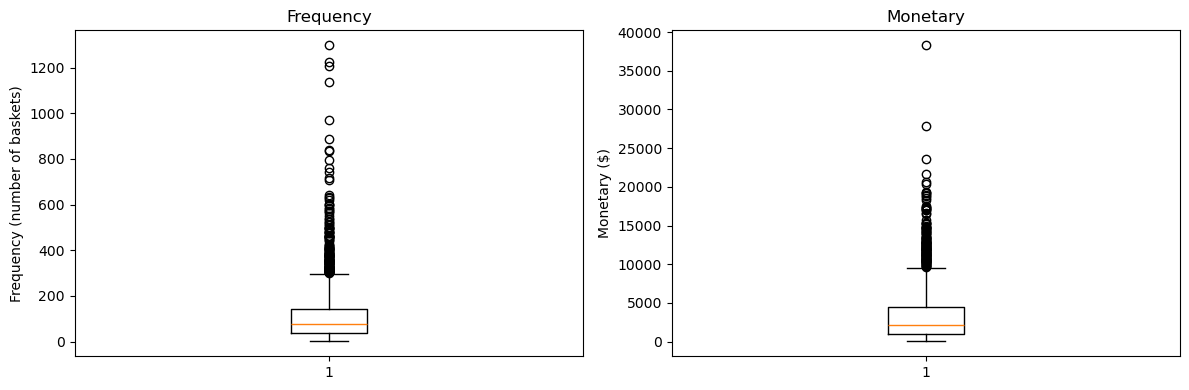

,household_key,recency,frequency,monetary,avg_ticket,segment
1022,1023,1,601,38319.79,63.76,Champions
1608,1609,0,408,27859.68,68.28,Champions
2321,2322,0,323,23646.92,73.21,Champions
1452,1453,1,761,21661.29,28.46,Champions
2458,2459,7,970,20671.50,21.31,Loyal Customers


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(rfm["frequency"])
axes[0].set_title("Frequency")
axes[0].set_ylabel("Frequency (number of baskets)")
axes[1].boxplot(rfm["monetary"])
axes[1].set_title("Monetary")
axes[1].set_ylabel("Monetary ($)")
plt.tight_layout()
plt.show()

top_monetary_outliers = rfm.nlargest(5, "monetary")[
    ["household_key", "recency", "frequency", "monetary", "avg_ticket", "segment"]
]
top_monetary_outliers

The boxplots confirm this visually: a dense cluster of points above the upper whisker in both variables, no outliers below (expected, since neither frequency nor spend can go negative).

Inspecting the top 5 monetary outliers, they tell a coherent story rather than looking like data errors: all 5 are `Champions` or `Loyal Customers`, with recency between 0 and 7 days, and average ticket sizes (21–73) that are large but not implausible for high-frequency shoppers. These look like genuinely high-value customers, not corrupted records, exactly the kind of household a retailer would want a clustering algorithm to identify as its own segment, rather than have `03_clustering.ipynb` treat them as noise to be removed.

### 7.1 Persisting the RFM Table

The `rfm` DataFrame currently exists only in this notebook's memory. For `03_clustering.ipynb` to run independently, without requiring this notebook to have been executed first in the same session, we persist it as a table in PostgreSQL, consistent with this project's SQL-first architecture. A primary key on `household_key` is added after the load, and the persisted row count is verified against the source `rfm` DataFrame via SQL, not just assumed from `to_sql()` completing without error.

In [13]:
with engine.begin() as conn:
    conn.execute(text("DROP TABLE IF EXISTS rfm_household;"))

rfm.to_sql("rfm_household", engine, if_exists="append", index=False)

with engine.begin() as conn:
    conn.execute(text("ALTER TABLE rfm_household ADD PRIMARY KEY (household_key);"))
    count = conn.execute(text("SELECT COUNT(*) FROM rfm_household")).scalar()

print(f"rfm_household: {count} rows persisted.")
assert count == len(rfm)

rfm_household: 2500 rows persisted.


## 8. Conclusion

This notebook set out to answer: which households are currently most valuable, and how often do they buy?

A complete, traceable RFM table was built for all 2,500 households in `transaction_data`, computed directly in SQL from the PostgreSQL database loaded in `01_data_setup_and_loading.ipynb`. Each design decision was checked against the data rather than assumed: recency measured against the dataset's last available day (not system time), frequency counted as distinct baskets rather than transaction lines, monetary as total accumulated spend with average ticket kept as a separate supporting variable, and rows with non-positive `sales_value` excluded and quantified (0.73% against the loaded table; the 29 rows more than the CSV count in `01_data_setup_and_loading.ipynb` come from rounding to cents on load, Section 2). The overlap check in Section 2 also confirmed that `sales_value <= 0` and `quantity <= 0` are largely separate conditions, supporting the choice to filter only on `sales_value`.

RFM scoring was validated for strict monotonicity across all three dimensions on the full 2,500 households, not just spot-checked (with one stated limitation: tied values, common in `recency`, are split across quintiles by row order, Section 4), and the Section 3 join was checked explicitly to confirm no household was dropped for lacking a qualifying transaction. A rule-based segmentation was applied as a descriptive baseline: `Champions` and `Loyal Customers` together account for 46.0% of households but 73.0% of accumulated monetary value, while also surfacing a concrete limitation: quintile scores rank each household against the whole population, so a rule like `At Risk` can't tell an unusually long gap for a frequent buyer from a normal one for an occasional buyer (Section 5). This is one reason the project uses a separate clustering notebook rather than treating RFM quartiles as the final segmentation.

Outliers were detected using the IQR method, chosen over z-scores given the right-skewed distributions confirmed early in the notebook (Section 3.1), and interpreted rather than just counted: the top monetary outliers are coherent high-value, high-frequency, low-recency households, not data errors, and the frequency/monetary outlier sets were cross-checked for overlap as groundwork for `03_clustering.ipynb`'s outlier tier. No outlier treatment happens here; that decision is deferred to `03_clustering.ipynb`, where it can be made in light of whichever algorithm is chosen and how sensitive it is to scale.

`02_rfm.ipynb` is complete. `03_clustering.ipynb` inherits a validated `rfm_household` table in PostgreSQL, a documented outlier profile, and an open question to test algorithmically: does clustering find segments that simple RFM quartiles miss?